# Lucrare de laborator nr. 7: Transformers (documentul: „Laboratorul 5”)
## Atenția: de la calculul de mână la un model real

**Student:** Daniel Pănuța, grupa IASD 2501 · **Disciplina:** Inteligența artificială generativă · **Profesor:** V. Ursachi

Documentul primit se numește „Laboratorul 5”, după Lecția 5 (Transformers). În numerotarea laboratoarelor de la disciplină este lucrarea nr. 7.

**Obiectiv:** verific practic pașii din Lecția 5:

- implementez atenția de la zero în NumPy și o verific pe exemplul rezolvat din curs (pașii 4–7, 9, 14);
- compar cum împart textul românesc trei tokenizere (pasul 1);
- obțin probabilitățile pentru următorul token și generez text token cu token, la diferite temperaturi (pașii 13 și 17);
- partea opțională: arăt că același cuvânt („bancă”) primește vectori diferiți în contexte diferite și vizualizez atenția (pașii 2, 8, 9).

**Structura:** urmez exact documentul. Golurile `___` din cod sunt completate, iar fiecare valoare de verificare din document e testată cu `assert`, deci notebook-ul arată singur că verificările trec. Răspunsurile la întrebările din secțiunea 7 a documentului sunt la final, cu numerele obținute aici.

**Mediul:** totul rulează pe procesor (CPU), fără GPU, cum spune documentul. Am rulat local, pe un MacBook M3.

## 2. Pregătirea: descărcarea modelelor

Descarc o singură dată tokenizerele și modelele folosite mai jos: GPT-2, BERT multilingv, BERT românesc și, pentru partea opțională 3.3, RoGPT2.

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "bertviz"], check=True)

import transformers, torch
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM

MODELE_TOKENIZER = ["gpt2", "bert-base-multilingual-cased",
                    "dumitrescustefan/bert-base-romanian-cased-v1"]
for nume in MODELE_TOKENIZER:
    AutoTokenizer.from_pretrained(nume)

AutoModelForCausalLM.from_pretrained("gpt2")
AutoModel.from_pretrained("dumitrescustefan/bert-base-romanian-cased-v1")
print(f"PyTorch {torch.__version__} | transformers {transformers.__version__}")
print("Gata: modelele sunt descărcate.")

PyTorch 2.15.0 | transformers 4.57.6
Gata: modelele sunt descărcate.


# Partea 1. Atenția în NumPy

## Sarcina 1.1. Softmax stabil numeric

Softmax transformă scorurile în ponderi pozitive cu suma 1: $\text{softmax}(s)_i = \dfrac{e^{s_i}}{\sum_j e^{s_j}}$ (pasul 6 din lecție).

Scad maximul de pe fiecare rând înainte de exponențiere. Folosesc `axis=-1, keepdims=True`, ca funcția să lucreze și pe matrice, rând cu rând.

In [2]:
import numpy as np
np.set_printoptions(precision=3, suppress=True)

def softmax(s):
    e = np.exp(s - s.max(axis=-1, keepdims=True))   # scădem maximul de pe fiecare rând
    return e / e.sum(axis=-1, keepdims=True)        # împărțim la suma de pe fiecare rând

p = softmax(np.array([1.2, 2.8, 0.7]))
print(p)
assert np.allclose(p, [0.152, 0.755, 0.092], atol=5e-4)
print("Verificare 1.1 trecută: [0.152 0.755 0.092]")

[0.152 0.755 0.092]
Verificare 1.1 trecută: [0.152 0.755 0.092]


Acum compar softmax „naiv” (fără scăderea maximului) cu varianta mea, pe scorurile `[1000, 1001]`:

In [3]:
import warnings
s = np.array([1000.0, 1001.0])
with warnings.catch_warnings(record=True) as avertismente:
    warnings.simplefilter("always")
    naiv = np.exp(s) / np.exp(s).sum()              # varianta naivă
print("naiv:   ", naiv)
for a in avertismente:
    print("   avertisment NumPy:", a.category.__name__, "-", a.message)
stabil = softmax(s)
print("stabil: ", stabil)
with np.errstate(over="ignore"):
    print("exp(1000) în float64 =", np.exp(np.float64(1000)), "| cel mai mare float64 ≈", np.finfo(np.float64).max)
print("scorurile după scăderea maximului:", s - s.max(), "→ exp:", np.exp(s - s.max()))
assert np.isnan(naiv).all() and np.allclose(stabil, [0.269, 0.731], atol=5e-4)

naiv:    [nan nan]
   avertisment NumPy: RuntimeWarning - overflow encountered in exp
   avertisment NumPy: RuntimeWarning - overflow encountered in exp
   avertisment NumPy: RuntimeWarning - invalid value encountered in divide
stabil:  [0.269 0.731]
exp(1000) în float64 = inf | cel mai mare float64 ≈ 1.7976931348623157e+308
scorurile după scăderea maximului: [-1.  0.] → exp: [0.368 1.   ]


## Sarcina 1.2. Funcția de atenție, verificată pe exemplul din curs

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

Scorurile sunt produsele scalare dintre interogarea $q$ și fiecare cheie $k$, împărțite la $\sqrt{d_k}$ (pasul 5). Masca, dacă există, pune $-\infty$ pe pozițiile interzise, iar Softmax le transformă în ponderea 0.

In [4]:
def attention(Q, K, V, mask=None):
    d_k = K.shape[-1]
    scores = Q @ K.T / np.sqrt(d_k)                  # Q·Kᵀ / √d_k
    if mask is not None:
        scores = np.where(mask, scores, -np.inf)
    weights = softmax(scores)
    return weights @ V, weights

# Datele din exemplul rezolvat (Lecția 5, după pasul 7)
q = np.array([[2, 1, 0, 1]])                     # q pentru „aprobat”
K = np.array([[0.5, 1.0, 0.3, 0.4],              # k pentru „Banca”
              [2.0, 1.0, 0.5, 0.6],              # k pentru „creditul”
              [0.2, 0.6, 0.9, 0.4]])             # k pentru „clientului”
V = np.array([[1.0, 0.0],
              [0.0, 1.0],
              [0.5, 0.5]])

z, w = attention(q, K, V)
print("scoruri:", (q @ K.T / np.sqrt(4))[0])
print("ponderi:", w)
print("z:", z)
assert np.allclose(w, [[0.152, 0.755, 0.092]], atol=5e-4) and np.allclose(z, [[0.199, 0.801]], atol=5e-4)

# de ce lecția a obținut (0,195; 0,805): ponderile rotunjite la două zecimale
w_rot = np.array([[0.15, 0.76, 0.09]])
print("cu ponderile rotunjite (0,15; 0,76; 0,09):", w_rot @ V)
print("Verificare 1.2 trecută.")

scoruri: [1.2 2.8 0.7]
ponderi: [[0.152 0.755 0.092]]
z: [[0.199 0.801]]
cu ponderile rotunjite (0,15; 0,76; 0,09): [[0.195 0.805]]
Verificare 1.2 trecută.


**Observație:**

- Scorurile ies exact 1,2; 2,8 și 0,7, ca în pasul 5. Ponderile sunt 0,152; 0,755 și 0,092, deci „aprobat” se uită 75,5% la „creditul”.
- Rezultatul $z = (0{,}199;\ 0{,}801)$ e cel exact. Lecția a obținut $(0{,}195;\ 0{,}805)$ pentru că a calculat cu ponderile rotunjite (0,15; 0,76; 0,09). Celula de mai sus reproduce exact acea valoare.

## Sarcina 1.3. Toți tokenii deodată, cu mască

O „propoziție” de 4 tokeni × 8 componente și trei matrice $W$ aleatoare, toate dintr-un generator cu seed fix (42). Q, K și V se obțin înmulțind tokenii cu matricele $W$ (pasul 4).

**Atenție:** nu schimb ordinea apelurilor `rng`. Sarcina 1.4 continuă din același generator, iar valorile de verificare depind de această ordine.

Masca `np.tril` e triunghiulară inferior: tokenul $i$ poate vedea doar tokenii $0 \dots i$ (pasul 14, atenția mascată din decoder).

In [5]:
rng = np.random.default_rng(42)
X = rng.normal(size=(4, 8))                        # 4 tokeni × 8 componente
W_Q, W_K, W_V = (rng.normal(size=(8, 4)) for _ in range(3))

Q, K, V = X @ W_Q, X @ W_K, X @ W_V                # pasul 4 din lecție
mask = np.tril(np.ones((4, 4), dtype=bool))        # True = tokenul poate fi văzut
print(mask)

Z, W = attention(Q, K, V, mask)
print(W)
print("Suma pe rânduri:", W.sum(axis=1))

assert np.allclose(W.sum(axis=1), 1)
assert np.allclose(W[np.triu_indices(4, k=1)], 0)
assert np.allclose(W[0], [1, 0, 0, 0])
assert np.allclose(W[1], [0.648, 0.352, 0, 0], atol=5e-4)
print("Verificare 1.3 trecută: sume = 1, zerouri deasupra diagonalei, rândul 1 = [1 0 0 0], rândul 2 = [0.648 0.352 0 0]")

[[ True False False False]
 [ True  True False False]
 [ True  True  True False]
 [ True  True  True  True]]
[[1.    0.    0.    0.   ]
 [0.648 0.352 0.    0.   ]
 [0.491 0.145 0.363 0.   ]
 [0.285 0.341 0.281 0.093]]
Suma pe rânduri: [1. 1. 1. 1.]
Verificare 1.3 trecută: sume = 1, zerouri deasupra diagonalei, rândul 1 = [1 0 0 0], rândul 2 = [0.648 0.352 0 0]


In [6]:
# pentru comparație: aceleași date FĂRĂ mască (encoder: fiecare token îi vede pe toți)
_, W_fara = attention(Q, K, V)
print("Ponderi fără mască:\n", W_fara)

Ponderi fără mască:
 [[0.413 0.044 0.334 0.209]
 [0.241 0.131 0.332 0.297]
 [0.44  0.13  0.326 0.103]
 [0.285 0.341 0.281 0.093]]


## Sarcina 1.4. Multi-head attention cu două capete

Fiecare cap are propriile matrice $W_Q, W_K, W_V$, deci poate urmări alt tip de relație. Ieșirile capetelor (câte 4 componente fiecare) se concatenează în 8 componente. Matricea $W_O$ (8 × 8) le combină apoi într-un singur vector pentru fiecare token (pasul 9).

In [7]:
def multi_head(X, heads, W_O):
    # heads = listă de tupluri (W_Q, W_K, W_V), câte unul pe cap
    outs = [attention(X @ Wq, X @ Wk, X @ Wv)[0] for Wq, Wk, Wv in heads]
    concat = np.concatenate(outs, axis=-1)
    return concat @ W_O               # matricea care combină capetele

heads = [tuple(rng.normal(size=(8, 4)) for _ in range(3)) for _ in range(2)]
W_O = rng.normal(size=(8, 8))
out = multi_head(X, heads, W_O)
print("ieșirea fiecărui cap:", [attention(X @ Wq, X @ Wk, X @ Wv)[0].shape for Wq, Wk, Wv in heads])
print("după concatenare:", np.concatenate([attention(X @ Wq, X @ Wk, X @ Wv)[0] for Wq, Wk, Wv in heads], axis=-1).shape)
print(out.shape)
assert out.shape == (4, 8)
print("Verificare 1.4 trecută: (4, 8)")

ieșirea fiecărui cap: [(4, 4), (4, 4)]
după concatenare: (4, 8)
(4, 8)
Verificare 1.4 trecută: (4, 8)


# Partea 2. Tokenizarea

Comparăm trei modele:

- **GPT-2:** antrenat mai ales pe engleză, cu tokenizare BPE la nivel de octeți;
- **BERT multilingv:** 104 limbi, WordPiece;
- **BERT românesc** (`dumitrescustefan/bert-base-romanian-cased-v1`): antrenat special pe română.

La GPT-2, literele românești apar ca simboluri ciudate (de exemplu `Ä`), pentru că o literă ca „ă” are 2 octeți în UTF-8. `Ġ` marchează un spațiu înaintea tokenului. La BERT, `##` marchează continuarea unui cuvânt.

In [8]:
import pandas as pd

nume_modele = {
    "GPT-2":           "gpt2",
    "BERT multilingv": "bert-base-multilingual-cased",
    "BERT românesc":   "dumitrescustefan/bert-base-romanian-cased-v1",
}
tokenizere = {nume: AutoTokenizer.from_pretrained(m)
              for nume, m in nume_modele.items()}
fraze = ["Banca a aprobat creditul clientului.",
         "Împrumuturile restructurate au dobânzi variabile."]

for nume, tok in tokenizere.items():
    for f in fraze:
        t = tok.tokenize(f)
        print(f"{nume:16} {len(t):3}  {t}")

GPT-2             12  ['B', 'anca', 'Ġa', 'Ġa', 'pro', 'bat', 'Ġcredit', 'ul', 'Ġclient', 'ul', 'ui', '.']
GPT-2             20  ['Ã', 'İ', 'm', 'pr', 'um', 'ut', 'ur', 'ile', 'Ġrestruct', 'urate', 'Ġau', 'Ġdo', 'b', 'Ã¢', 'n', 'zi', 'Ġvari', 'ab', 'ile', '.']
BERT multilingv   10  ['Banca', 'a', 'ap', '##ro', '##bat', 'credit', '##ul', 'client', '##ului', '.']
BERT multilingv   15  ['Î', '##mp', '##rumu', '##turi', '##le', 'rest', '##ru', '##ctura', '##te', 'au', 'dob', '##ân', '##zi', 'variabile', '.']
BERT românesc      6  ['Banca', 'a', 'aprobat', 'creditul', 'clientului', '.']
BERT românesc      8  ['Împrum', '##uturile', 'restruct', '##urate', 'au', 'dobânzi', 'variabile', '.']


## Sarcina 2.1. Tabelul cu numărul de tokeni

Construiesc tabelul automat, ca să nu greșesc la transcriere. Adaug și numărul de cuvinte și „tokeni pe cuvânt”, care arată cât de bine se potrivește vocabularul modelului cu româna.

In [9]:
tabel = pd.DataFrame({f"Fraza {j+1}": [len(tok.tokenize(f)) for tok in tokenizere.values()]
                      for j, f in enumerate(fraze)}, index=list(tokenizere))
for j, f in enumerate(fraze):
    tabel[f"tokeni/cuvânt F{j+1}"] = (tabel[f"Fraza {j+1}"] / len(f.rstrip('.').split())).round(2)
print("Cuvinte:", [len(f.rstrip('.').split()) for f in fraze])
tabel

Cuvinte: [5, 5]


,Fraza 1,Fraza 2,tokeni/cuvânt F1,tokeni/cuvânt F2
GPT-2,12,20,2.4,4.0
BERT multilingv,10,15,2.0,3.0
BERT românesc,6,8,1.2,1.6


**Tabelul 2.1, completat:**

| Model | Fraza 1 („Banca a aprobat creditul clientului.”) | Fraza 2 („Împrumuturile restructurate au dobânzi variabile.”) |
|---|---|---|
| GPT-2 | 12 | 20 |
| BERT multilingv | 10 | 15 |
| BERT românesc | 6 | 8 |

**Observații:**

- **BERT românesc** păstrează aproape toate cuvintele întregi: „aprobat”, „creditul”, „clientului”, „dobânzi”. Are 1,2–1,6 tokeni pe cuvânt.
- **GPT-2** taie cuvintele în bucăți fără sens („B / anca”, „a / pro / bat”). Literele cu diacritice devin octeți separați: „Î” → `Ã` + `İ`, „â” → `Ã¢`. Ajunge la 4 tokeni pe cuvânt la fraza 2.
- **BERT multilingv** e la mijloc: știe „Banca” și „variabile”, dar sparge „Împrumuturile” în 5 bucăți.
- Cu cât vocabularul modelului a văzut mai multă română, cu atât sunt mai puțini tokeni.

## Sarcina 2.2. Cât „costă” limba română?

Serviciile API se plătesc per token, iar fereastra de context se măsoară tot în tokeni. Număr tokenii GPT-2 pentru aceeași frază în română și în engleză. Calculez apoi costul pentru 1 milion de fraze, la 1 dolar pentru 1 milion de tokeni.

In [10]:
gpt2 = tokenizere["GPT-2"]
n_ro = len(gpt2.tokenize("Banca a aprobat creditul clientului."))
n_en = len(gpt2.tokenize("The bank approved the client's loan."))
print(n_ro, n_en, round(n_ro / n_en, 2))
print("EN:", gpt2.tokenize("The bank approved the client's loan."))

PRET = 1.0 / 1_000_000          # dolari pe token
N_FRAZE = 1_000_000
for limba, n in [("română", n_ro), ("engleză", n_en)]:
    print(f"Cost pentru {N_FRAZE:,} fraze în {limba}: {n} tokeni × {N_FRAZE:,} × 1 $/1M = {n * N_FRAZE * PRET:,.0f} $")

12 8 1.5
EN: ['The', 'Ġbank', 'Ġapproved', 'Ġthe', 'Ġclient', "'s", 'Ġloan', '.']
Cost pentru 1,000,000 fraze în română: 12 tokeni × 1,000,000 × 1 $/1M = 12 $
Cost pentru 1,000,000 fraze în engleză: 8 tokeni × 1,000,000 × 1 $/1M = 8 $


## Sarcina 2.3. Diacriticele cu virgulă și cu sedilă

ș, ț (virgulă, U+0219 / U+021B) sunt forma corectă. ş, ţ (sedilă, U+015F / U+0163) sunt o formă veche, încă frecventă. Pentru calculator sunt caractere diferite, chiar dacă pe ecran arată aproape la fel.

In [11]:
ro = tokenizere["BERT românesc"]
t_virgula = ro.tokenize("știință și țară")     # ș, ț cu virgulă
t_sedila = ro.tokenize("ştiinţă şi ţară")      # ş, ţ cu sedilă
print(len(t_virgula), t_virgula)
print(len(t_sedila), t_sedila)
print("Coduri Unicode:", [f"{c} U+{ord(c):04X}" for c in "șşțţ"])

# aceeași preprocesare ca în Lab 6: transformarea sedilei în virgulă
SEDILA = str.maketrans({"ş": "ș", "ţ": "ț", "Ş": "Ș", "Ţ": "Ț"})
normalizat = "ştiinţă şi ţară".translate(SEDILA)
print("După normalizare:", ro.tokenize(normalizat), "| identic cu varianta cu virgulă:", ro.tokenize(normalizat) == t_virgula)
for nume, tok in tokenizere.items():
    print(f"{nume:16} virgulă: {len(tok.tokenize('știință și țară')):2} tokeni | sedilă: {len(tok.tokenize('ştiinţă şi ţară')):2} tokeni")

3 ['știință', 'și', 'țară']
3 ['[UNK]', '[UNK]', '[UNK]']
Coduri Unicode: ['ș U+0219', 'ş U+015F', 'ț U+021B', 'ţ U+0163']
După normalizare: ['știință', 'și', 'țară'] | identic cu varianta cu virgulă: True
GPT-2            virgulă: 18 tokeni | sedilă: 15 tokeni
BERT multilingv  virgulă:  5 tokeni | sedilă:  7 tokeni
BERT românesc    virgulă:  3 tokeni | sedilă:  3 tokeni


# Partea 3. Generarea textului

Folosim GPT-2, un model „doar decoder” (lecția, secțiunea 6), cu text în engleză, limba pe care a fost antrenat.

## Sarcina 3.1. Probabilitățile pentru următorul token

Modelul întoarce un vector **logits** pentru fiecare poziție. Ne interesează doar **ultima** poziție: scorurile ei sunt pentru tokenul care urmează. Softmax le transformă în probabilități peste tot vocabularul (pasul 13).

In [12]:
tok = tokenizere["GPT-2"]
model = AutoModelForCausalLM.from_pretrained("gpt2")
model.eval()

def top10(model, tok, text):
    ids = tok(text, return_tensors="pt").input_ids
    with torch.no_grad():
        logits = model(ids).logits[0, -1]       # scorurile pentru ULTIMA poziție
    print("Dimensiunea vectorului logits:", logits.shape)
    probs = torch.softmax(logits, dim=-1)
    print("Suma probabilităților:", probs.sum().item())
    top = torch.topk(probs, 10)
    for p, i in zip(top.values, top.indices):
        print(f"{tok.decode(int(i))!r:16} {p.item():.3f}")
    return probs

probs_gpt2 = top10(model, tok, "The bank approved the")
print("Mărimea vocabularului GPT-2:", tok.vocab_size, "| probabilitatea cumulată a primilor 10:", round(torch.topk(probs_gpt2, 10).values.sum().item(), 3))

Dimensiunea vectorului logits: torch.Size([50257])
Suma probabilităților: 1.0000221729278564
' loan'          0.066
' deal'          0.066
' sale'          0.037
' transaction'   0.033
' plan'          0.025
' purchase'      0.024
' new'           0.019
' $'             0.019
' move'          0.016
' settlement'    0.012
Mărimea vocabularului GPT-2: 50257 | probabilitatea cumulată a primilor 10: 0.316


## Sarcina 3.2. Bucla de generare, scrisă de mână

Bucla din pasul 17: **prezice → alege → adaugă → repetă**.

- **Greedy:** alege mereu tokenul cu scorul maxim (`argmax`).
- **Sampling:** împarte logits la temperatura $T$, aplică Softmax și extrage aleator un token după aceste probabilități: $p_i = \dfrac{e^{z_i / T}}{\sum_j e^{z_j / T}}$.

**Reproductibilitate:** fixez `torch.manual_seed(42)` înainte de experimente, deci la o nouă rulare se obțin aceleași texte. Documentul cere însă două încercări pentru fiecare temperatură. Cele două încercări de la aceeași temperatură diferă între ele, pentru că generatorul aleator merge mai departe: variabilitatea e voită.

In [13]:
def genereaza(model, tok, text, n_tokeni=25, temperatura=1.0, greedy=False):
    ids = tok(text, return_tensors="pt").input_ids
    for _ in range(n_tokeni):
        with torch.no_grad():
            logits = model(ids).logits[0, -1]
        if greedy:
            urm = torch.argmax(logits)                         # tokenul cu scor maxim
        else:
            probs = torch.softmax(logits / temperatura, dim=-1)  # temperatura
            urm = torch.multinomial(probs, 1)[0]  # extragere aleatoare
        ids = torch.cat([ids, urm.view(1, 1)], dim=1)  # adăugăm tokenul
    return tok.decode(ids[0])

torch.manual_seed(42)
text = "The bank approved the"
GEN = {"greedy": [genereaza(model, tok, text, greedy=True), genereaza(model, tok, text, greedy=True)]}
print("GREEDY:", GEN["greedy"][0])
print("GREEDY (a doua oară, identic?):", GEN["greedy"][0] == GEN["greedy"][1])
for T in [0.2, 0.7, 1.5]:
    GEN[T] = []
    for incercare in range(2):
        GEN[T].append(genereaza(model, tok, text, temperatura=T))
        print(f"T = {T}:", GEN[T][-1])

GREEDY: The bank approved the loan in May, but the bank has not yet approved the loan.

The bank said it will not be able to
GREEDY (a doua oară, identic?): True


T = 0.2: The bank approved the deal on Friday, saying it would help the country's economy.

The deal would allow the government to provide a loan


T = 0.2: The bank approved the deal on July 1, but it has not yet been finalized.

The bank has been under pressure from the government to


T = 0.7: The bank approved the loan, which will be repaid over a five-year period.

Banks are expected to cut 438 jobs in


T = 0.7: The bank approved the plan after the National Bank of Ireland announced plans to expand its capacity to 46,000 customers, with the intention of increasing the


T = 1.5: The bank approved the infinite 49 designs he came up Seventh Thinking Concepts projects venture 4 fourth neurological mort commonly Bye Wis 殇闪告


T = 1.5: The bank approved the loan of Rs 4 Bakota her Canadian Memoula is donating Airways cruise donations of female comrades in almost 25 Centers came Om


**Cum schimbă temperatura distribuția.** Calculez probabilitatea primului token și **entropia** distribuției pentru fiecare $T$, pe același prompt. Entropia e cu atât mai mare cu cât probabilitatea e mai „împrăștiată”.

In [14]:
with torch.no_grad():
    logits0 = model(tok(text, return_tensors="pt").input_ids).logits[0, -1]
rows = []
for T in [0.2, 0.7, 1.0, 1.5]:
    p = torch.softmax(logits0 / T, dim=-1)
    top = torch.topk(p, 3)
    rows.append({"T": T, "top-1": f"{tok.decode(int(top.indices[0]))!r} {top.values[0]:.3f}",
                 "top-2": f"{tok.decode(int(top.indices[1]))!r} {top.values[1]:.3f}",
                 "top-3": f"{tok.decode(int(top.indices[2]))!r} {top.values[2]:.3f}",
                 "tokeni pentru 90% din probabilitate": int((torch.cumsum(torch.sort(p, descending=True).values, 0) < 0.9).sum()) + 1,
                 "entropie (biți)": round(float(-(p * torch.log2(p.clamp_min(1e-12))).sum()), 2)})
pd.DataFrame(rows)

,T,top-1,top-2,top-3,tokeni pentru 90% din probabilitate,entropie (biți)
0,0.2,' loan' 0.482,' deal' 0.467,' sale' 0.027,2,1.33
1,0.7,' loan' 0.175,' deal' 0.174,' sale' 0.077,79,5.40
2,1.0,' loan' 0.066,' deal' 0.066,' sale' 0.037,1767,8.97
3,1.5,' loan' 0.013,' deal' 0.013,' sale' 0.009,11243,12.51


**Tabelul de observații** (din textele generate mai sus; la sampling, câte 2 încercări):

| Setare | Ce am observat |
|---|---|
| Greedy | Primul rând e coerent, dar **repetitiv și circular**: „approved the loan …, but the bank has not yet approved the loan”. A doua rulare dă **exact același text** (`True`). |
| T = 0,2 | **Coerent**, stil de știre economică, foarte apropiat de greedy. Ambele încercări încep cu „approved the deal”. Diferă doar detaliile (on Friday / on July 1). |
| T = 0,7 | **Coerent și variat:** cele două încercări merg în direcții diferite („the loan … five-year period”, „the plan after the National Bank of Ireland…”). Apar detalii **inventate**, dar plauzibile (438 de locuri de muncă, 46.000 de clienți). |
| T = 1,5 | **Incoerent:** cuvinte fără legătură („infinite 49 designs … neurological mort commonly Bye”), nume și cifre aleatoare, chiar caractere chinezești. Gramatica se pierde după 2–3 cuvinte. |

**De ce:** tabelul de mai sus arată cum se schimbă distribuția primului token.

- La T = 0,2, „loan” (0,482) și „deal” (0,467) iau aproape toată probabilitatea: entropia e 1,33 biți, iar doar 2 tokeni acoperă 90% din probabilitate. De aceea ambele încercări au ales „deal”, practic un „greedy” cu două variante.
- La T = 1,5, aceleași două cuvinte au doar 0,013 fiecare. Entropia ajunge la 12,51 biți, iar pentru 90% din probabilitate e nevoie de **11.243 de tokeni**. Modelul extrage astfel des tokeni rari și nepotriviți.

## Sarcina 3.3 (opțională). Un model pentru limba română: RoGPT2

Repet 3.1 și 3.2 cu `readerbench/RoGPT2-base`, un GPT-2 antrenat pe română, cu promptul „Banca a aprobat”. Folosesc același seed.

In [15]:
tok_ro_gpt = AutoTokenizer.from_pretrained("readerbench/RoGPT2-base")
model_ro_gpt = AutoModelForCausalLM.from_pretrained("readerbench/RoGPT2-base")
model_ro_gpt.eval()
_ = top10(model_ro_gpt, tok_ro_gpt, "Banca a aprobat")
print("Tokenizarea promptului:", tok_ro_gpt.tokenize("Banca a aprobat"), "| GPT-2:", len(gpt2.tokenize("Banca a aprobat")), "tokeni")
print("RoGPT2, fraza 1:", len(tok_ro_gpt.tokenize(fraze[0])), "tokeni | fraza 2:", len(tok_ro_gpt.tokenize(fraze[1])), "tokeni")
torch.manual_seed(42)
print("GREEDY:", genereaza(model_ro_gpt, tok_ro_gpt, "Banca a aprobat", greedy=True))
for incercare in range(2):
    print("T = 0.7:", genereaza(model_ro_gpt, tok_ro_gpt, "Banca a aprobat", temperatura=0.7))

Dimensiunea vectorului logits: torch.Size([50257])
Suma probabilităților: 1.0000250339508057
' în'            0.108
' un'            0.075
','              0.060
' o'             0.050
'-'              0.049
' finanțarea'    0.013
' planul'        0.013
' pentru'        0.013
' la'            0.012
' și'            0.010
Tokenizarea promptului: ['B', 'anca', 'Ġa', 'Ġaprobat'] | GPT-2: 6 tokeni
RoGPT2, fraza 1: 7 tokeni | fraza 2: 9 tokeni


GREEDY: Banca a aprobat în octombrie 2018 un împrumut de 1,5 miliarde de euro de la Banca Europeană de Investiții (BEI) pentru finanțarea proiectelor


T = 0.7: Banca a aprobat să investească un capital de 11 milioane de dolari în modernizarea și extinderea infrastructurii de transport. La începutul anului 2019, a fost semnat


T = 0.7: Banca a aprobat în luna octombrie 2019 un împrumut de 1,3 miliarde de euro prin intermediul Uniunii Europene (UE), pentru a finanța achiziționarea


**Observație 3.3 (RoGPT2):**

- **Tokenizarea:** RoGPT2 împarte „Banca a aprobat” în 4 tokeni, față de 6 la GPT-2. Frazele de la 2.1 au 7 și 9 tokeni, față de 12 și 20 la GPT-2, aproape cât BERT-ul românesc.
- **Cele mai probabile continuări:** „ în” (0,108), „ un” (0,075) și „,” (0,060). Sunt cuvinte de legătură firești în română („Banca a aprobat **în** octombrie…”, „… **un** împrumut”). Vocabularul conține cuvinte întregi ca „ finanțarea” și „ planul”.
- **Textul generat:** gramatical corect, în stil de știre economică. Faptele sunt însă inventate: „un împrumut de 1,5 miliarde de euro de la BEI” în octombrie 2018. Modelul a învățat **forma** textelor bancare, nu fapte reale.
- **Greedy** nu s-a mai repetat la RoGPT2 în cei 25 de tokeni, spre deosebire de GPT-2.

# Partea 4 (opțională). Embeddings contextuale și vizualizarea atenției

## Sarcina 4.1. Vectorul lui „bancă” în patru propoziții

BERT-ul românesc are 12 blocuri:

- **stratul 0** e ieșirea din pasul 3 (embedding + poziție), încă fără context;
- **stratul 12** e ieșirea ultimului bloc.

Propozițiile 1–2 folosesc „bancă” cu sens **financiar**, iar 3–4 cu sensul de **loc de șezut**. Dacă atenția „înțelege” contextul (pasul 8), la stratul 12 vectorii 1–2 ar trebui să fie mai apropiați între ei decât de 3–4.

In [16]:
import torch.nn.functional as Fn
import matplotlib.pyplot as plt
%matplotlib inline

nume_ro = "dumitrescustefan/bert-base-romanian-cased-v1"
tok_bert = AutoTokenizer.from_pretrained(nume_ro)
bert = AutoModel.from_pretrained(nume_ro, output_hidden_states=True,
                                 attn_implementation="eager")
bert.eval()

def vector_cuvant(fraza, cuvant, strat):
    enc = tok_bert(fraza, return_tensors="pt")
    with torch.no_grad():
        out = bert(**enc)
    tokens = tok_bert.convert_ids_to_tokens(enc.input_ids[0])
    parti = tok_bert.tokenize(cuvant)       # cuvântul poate avea mai mulți tokeni
    for i in range(len(tokens) - len(parti) + 1):
        if tokens[i:i + len(parti)] == parti:
            return out.hidden_states[strat][0, i:i + len(parti)].mean(dim=0)
    raise ValueError(f"Nu am găsit „{cuvant}” în: {fraza}")

fraze_banca = ["Am deschis un cont la bancă.",
               "Am luat un credit de la bancă.",
               "M-am așezat pe o bancă în parc.",
               "Bătrânul stă pe bancă lângă fântână."]
print("„bancă” →", tok_bert.tokenize("bancă"))

SIM = {}
for strat in [0, 12]:
    vecs = torch.stack([vector_cuvant(f, "bancă", strat) for f in fraze_banca])
    sim = Fn.cosine_similarity(vecs.unsqueeze(1), vecs.unsqueeze(0), dim=-1)
    SIM[strat] = sim.numpy()
    print(f"Stratul {strat}:")
    print(sim.numpy().round(3))

„bancă” → ['bancă']


Stratul 0:
[[1.    0.971 0.971 0.961]
 [0.971 1.    1.    0.954]
 [0.971 1.    1.    0.954]
 [0.961 0.954 0.954 1.   ]]


Stratul 12:
[[1.    0.953 0.659 0.594]
 [0.953 1.    0.625 0.56 ]
 [0.659 0.625 1.    0.832]
 [0.594 0.56  0.832 1.   ]]


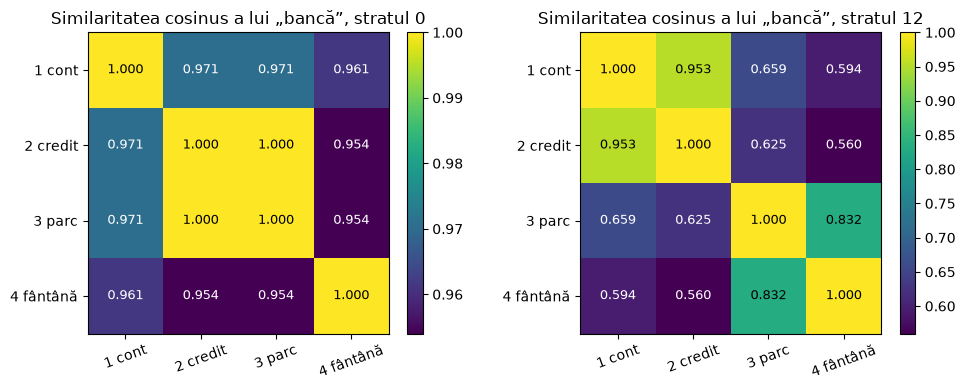

Stratul  0: 1–2 = 0.971 | 1–3 = 0.971 | medie același sens = 0.962 | medie sens diferit = 0.972 | diferență = -0.009
Stratul 12: 1–2 = 0.953 | 1–3 = 0.659 | medie același sens = 0.892 | medie sens diferit = 0.609 | diferență = +0.283


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
etich = ["1 cont", "2 credit", "3 parc", "4 fântână"]
for ax, strat in zip(axes, [0, 12]):
    im = ax.imshow(SIM[strat], cmap="viridis", vmin=SIM[strat].min(), vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{SIM[strat][i, j]:.3f}", ha="center", va="center", color="w" if SIM[strat][i, j] < SIM[strat].mean() else "k", fontsize=9)
    ax.set_xticks(range(4)); ax.set_xticklabels(etich, rotation=20); ax.set_yticks(range(4)); ax.set_yticklabels(etich)
    ax.set_title(f"Similaritatea cosinus a lui „bancă”, stratul {strat}")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

for strat in [0, 12]:
    S = SIM[strat]
    acelasi = np.mean([S[0, 1], S[2, 3]]); diferit = np.mean([S[i, j] for i in (0, 1) for j in (2, 3)])
    print(f"Stratul {strat:2d}: 1–2 = {S[0,1]:.3f} | 1–3 = {S[0,2]:.3f} | medie același sens = {acelasi:.3f} | "
          f"medie sens diferit = {diferit:.3f} | diferență = {acelasi - diferit:+.3f}")

## Sarcina 4.2. Vizualizarea atenției cu bertviz

`head_view` desenează un widget interactiv: alegi stratul din listă și dai clic pe un token ca să vezi la cine se uită fiecare cap.

Pe lângă widget, caut **numeric**, în tensorul `att`, capul (strat, cap) în care „aprobat” se uită cel mai mult la „creditul”. Dacă un cuvânt e împărțit în mai mulți sub-tokeni, adun atenția spre toți sub-tokenii lui și fac media pe sub-tokenii de la care pleacă atenția.

In [18]:
from bertviz import head_view

bert_att = AutoModel.from_pretrained(nume_ro, output_attentions=True,
                                     attn_implementation="eager")
enc = tok_bert("Banca a aprobat creditul clientului.", return_tensors="pt")
with torch.no_grad():
    att = bert_att(**enc).attentions
tokens_att = tok_bert.convert_ids_to_tokens(enc.input_ids[0])
head_view(att, tokens_att)

<IPython.core.display.Javascript object>

In [19]:
def pozitii(cuvant):
    parti = tok_bert.tokenize(cuvant)
    for i in range(len(tokens_att) - len(parti) + 1):
        if tokens_att[i:i + len(parti)] == parti:
            return list(range(i, i + len(parti)))
    raise ValueError(cuvant)

src, dst = pozitii("aprobat"), pozitii("creditul")
print("Tokeni:", tokens_att)
print("„aprobat” →", [tokens_att[i] for i in src], "| „creditul” →", [tokens_att[i] for i in dst])
A = torch.stack(att)[:, 0]                       # (straturi, capete, tokeni, tokeni)
print("Forma tensorului de atenție:", tuple(A.shape))
a2c = A[:, :, src][:, :, :, dst].sum(-1).mean(-1)   # (straturi, capete): atenția aprobat → creditul
top = torch.topk(a2c.flatten(), 5)
print("\nCapetele în care „aprobat” se uită cel mai mult la „creditul” (straturile și capetele numerotate de la 0, ca în bertviz):")
for v, idx in zip(top.values, top.indices):
    L, H = divmod(int(idx), A.shape[1])
    tinta = tokens_att[int(A[L, H, src].mean(0).argmax())]
    print(f"  stratul {L:2d}, capul {H:2d}: {v:.3f} (ținta preferată a lui „aprobat” în acest cap: {tinta!r})")
print(f"\nMedia pe toate cele {A.shape[0] * A.shape[1]} capete: {a2c.mean():.3f} | uniform ar fi 1/{len(tokens_att)} = {1/len(tokens_att):.3f}")

# capete greu de interpretat: unde aproape toată atenția merge la [CLS] / [SEP] / punct
speciale = [i for i, t in enumerate(tokens_att) if t in ("[CLS]", "[SEP]", ".")]
spec = A[:, :, :, speciale].sum(-1).mean(-1)
L, H = divmod(int(spec.flatten().argmax()), A.shape[1])
print(f"Capul cu cea mai mare atenție spre [CLS]/[SEP]/punct: stratul {L}, capul {H} ({spec[L, H]:.3f} din atenție, în medie pe tokeni)")

Tokeni: ['[CLS]', 'Banca', 'a', 'aprobat', 'creditul', 'clientului', '.', '[SEP]']
„aprobat” → ['aprobat'] | „creditul” → ['creditul']
Forma tensorului de atenție: (12, 12, 8, 8)

Capetele în care „aprobat” se uită cel mai mult la „creditul” (straturile și capetele numerotate de la 0, ca în bertviz):
  stratul  1, capul  3: 0.995 (ținta preferată a lui „aprobat” în acest cap: 'creditul')
  stratul  2, capul 10: 0.947 (ținta preferată a lui „aprobat” în acest cap: 'creditul')
  stratul  7, capul 11: 0.891 (ținta preferată a lui „aprobat” în acest cap: 'creditul')
  stratul  4, capul  7: 0.560 (ținta preferată a lui „aprobat” în acest cap: 'creditul')
  stratul  9, capul  7: 0.464 (ținta preferată a lui „aprobat” în acest cap: '[SEP]')

Media pe toate cele 144 capete: 0.099 | uniform ar fi 1/8 = 0.125
Capul cu cea mai mare atenție spre [CLS]/[SEP]/punct: stratul 6, capul 5 (0.955 din atenție, în medie pe tokeni)


**Observație 4.2:**

- **Tokenizarea:** BERT-ul românesc împarte propoziția în 8 tokeni, cu cuvintele întregi: `[CLS] Banca a aprobat creditul clientului . [SEP]`. Atenția „aprobat” → „creditul” se citește deci direct, fără sub-tokeni.
- **Capul cel mai clar: stratul 1, capul 3** (numerotare de la 0, ca în bertviz). Aici „aprobat” dă **99,5%** din atenție lui „creditul”. Urmează **stratul 2, capul 10** (94,7%) și **stratul 7, capul 11** (89,1%).
  - Media pe toate cele 144 de capete e de doar 9,9%, sub o atenție uniformă (1/8 = 12,5%). Doar câteva capete „s-au specializat” pe legătura verb → complement direct, cum spune pasul 9.
- **Un cap greu de interpretat: stratul 6, capul 5.** În medie, 95,5% din atenția fiecărui token merge spre `[CLS]`, `[SEP]` sau punct, adică spre tokeni fără conținut. E un tipar cunoscut la BERT: capul „nu face nimic” și parchează atenția pe tokenii speciali.
- **Ce n-am verificat vizual:** widget-ul bertviz e interactiv (JavaScript). Capetele de mai sus le-am găsit numeric, din tensorul `att`, și se pot verifica în widget: stratul 1 → capul 3 și stratul 6 → capul 5.

# 7. Răspunsuri la întrebări

**1. (Sarcina 1.1) Softmax naiv față de cel stabil pe `[1000, 1001]`.**

- **Varianta naivă** a dat `[nan nan]`, cu avertismentele NumPy „overflow encountered in exp” și „invalid value encountered in divide”. Varianta mea a dat `[0.269 0.731]`.
- **De ce:** $e^{1000}$ depășește cel mai mare număr `float64` (≈ 1,8·10³⁰⁸) și devine `inf`, iar `inf / inf = nan`.
- **Ce face scăderea maximului:** după scădere, scorurile devin $[-1, 0]$, iar $e^{-1} = 0{,}368$ și $e^0 = 1$ sunt numere mici; $0{,}368 / 1{,}368 = 0{,}269$.
- **De ce rezultatul corect nu se schimbă:** $\dfrac{e^{s_i - c}}{\sum_j e^{s_j - c}} = \dfrac{e^{-c}\, e^{s_i}}{e^{-c} \sum_j e^{s_j}}$, iar factorul $e^{-c}$ se simplifică. Softmax depinde doar de **diferențele** dintre scoruri, iar 1001 − 1000 = 1 rămâne același.

**2. (Sarcina 1.3) De ce primul rând mascat e `[1, 0, 0, 0]`? Ce vede al treilea token?**

- **Primul rând:** masca triunghiulară îi permite primului token să vadă **doar pe el însuși**. Celelalte trei scoruri devin $-\infty$, iar $e^{-\infty} = 0$. Softmax-ul unui singur scor finit e 1, oricare ar fi valoarea lui.
- **Al treilea token** vede primii trei tokeni (inclusiv pe el), nu și pe al patrulea. Ponderile lui sunt `[0.491 0.145 0.363 0]`: jumătate din atenție merge la primul token, iar cel de-al patrulea, „viitorul”, primește exact 0.
- **Fără mască**, același token ar fi dat 0,103 și tokenului 4 (celula de comparație). Masca e cea care împiedică decoder-ul să „vadă viitorul” (pasul 14).

**3. (Sarcina 2.2) Româna față de engleza la GPT-2; costul pentru 1 milion de fraze.**

- **Raportul:** fraza în română are **12 tokeni**, cea în engleză **8**, deci **de 1,5 ori mai mulți**.
- **Costul,** la 1 $ pentru 1 milion de tokeni:
  - română: 12 × 1.000.000 = 12 milioane de tokeni → **12 $**;
  - engleză: 8 × 1.000.000 = 8 milioane de tokeni → **8 $**.
- **Ce mai înseamnă:** același conținut în română costă cu 50% mai mult. În aceeași fereastră de context încape cu o treime mai puțin text românesc.
- **La fraza 2** e și mai rău: GPT-2 folosește 4 tokeni pe cuvânt (20 de tokeni pentru 5 cuvinte), față de 1,6 la BERT-ul românesc.

**4. (Sarcina 2.3) „știință” față de „ştiinţă”. Ce trebuie făcut cu textele românești?**

- **BERT-ul românesc:**
  - varianta cu virgulă dă 3 tokeni, cuvinte întregi: `['știință', 'și', 'țară']`;
  - varianta cu sedilă dă tot 3 tokeni, dar toți sunt **`[UNK]`** (necunoscut). Modelul pierde complet informația: pentru el, cele trei cuvinte sunt „ceva necunoscut”.
- **Celelalte modele:**
  - BERT multilingv: 5 tokeni cu virgulă, 7 cu sedilă (fragmente diferite: `##ță` față de `##ţ` + `##ă`);
  - GPT-2: 18 tokeni cu virgulă și 15 cu sedilă, alți octeți. Caracterele sunt diferite în Unicode: ș = U+0219, ş = U+015F.
- **Concluzia:** înainte de a da textele unui model, le **normalizez**: ş → ș, ţ → ț, Ş → Ș, Ţ → Ț, plus forma Unicode NFC. După normalizare, tokenizarea e identică cu varianta corectă (`True` în celula 2.3). Am făcut exact această normalizare în Lab 6 (RAG), la ingestia documentelor.

**5. (Sarcina 3.1) Dimensiunea logits la GPT-2 și primii trei tokeni.**

- **Dimensiunea:** vectorul logits are **50.257** de valori, cât **vocabularul GPT-2**: câte un scor pentru fiecare token posibil care ar putea urma.
- **Probabilitățile:** după Softmax, suma lor e 1,00002, adică 1, cu o mică eroare de rotunjire în `float32`.
- **Primii trei tokeni** după „The bank approved the”: **„ loan” 0,066**, **„ deal” 0,066** și **„ sale” 0,037**.
- **Cât de împrăștiată e distribuția:** primii 10 tokeni adună doar 31,6% din probabilitate. Modelul vede multe continuări posibile, toate legate de tranzacții (transaction, plan, purchase, settlement).

**6. (Sarcina 3.2) De ce greedy dă mereu același text? Ce face temperatura?**

- **Greedy** alege la fiecare pas `argmax` dintr-o funcție deterministă: aceleași ponderi și același prompt dau aceleași logits, deci același token. Nu există nicio sursă de aleatoriu. A doua rulare a dat exact același text (`True`). Fiindcă alege mereu varianta „cea mai sigură”, intră ușor în bucle („approved the loan… has not yet approved the loan”).
- **Temperatura:** $p_i = \dfrac{e^{z_i/T}}{\sum_j e^{z_j/T}}$. Raportul a două probabilități e $p_i / p_j = e^{(z_i - z_j)/T}$.
  - **T < 1** mărește diferențele dintre scoruri, iar distribuția se ascute spre primele variante. La T = 0,2, „loan” + „deal” au 95% din probabilitate (entropie 1,33 biți), deci textul e coerent, dar puțin variat.
  - **T > 1** micșorează diferențele, iar distribuția se aplatizează. La T = 1,5, cuvântul de top are doar 1,3%, iar 90% din probabilitate e împărțită între 11.243 de tokeni (entropie 12,51 biți). Se extrag des tokeni rari, deci textul devine incoerent (caractere chinezești, cuvinte fără legătură).
  - **T = 0,7** a fost compromisul: coerent și variat.

**7. (Partea 4) Similaritatea lui „bancă” la straturile 0 și 12.**

| Pereche | Stratul 0 | Stratul 12 |
|---|---|---|
| 1–2 (cont / credit, ambele financiare) | 0,971 | **0,953** |
| 1–3 (cont / parc, sensuri diferite) | 0,971 | **0,659** |
| 3–4 (parc / fântână, ambele loc de șezut) | 0,954 | **0,832** |

- **La stratul 0** toate valorile sunt 0,95–1,00 și nu țin cont de sens. Vectorul e embedding-ul cuvântului plus poziția (pasul 3), iar diferențele vin **doar din poziție**. Dovada: în propozițiile 2 și 3, „bancă” e pe aceeași poziție (7), iar similaritatea e exact **1,000**, deși sensurile sunt opuse.
- **La stratul 12** apar două grupuri clare:
  - perechile cu același sens: 0,953 (financiar) și 0,832 (șezut), în medie **0,892**;
  - perechile cu sens diferit: 0,56–0,66, în medie **0,609**.
- Diferența e de +0,283, mult mai mare decât cele „câteva sutimi” la care avertiza documentul. **Da:** la stratul 12, propozițiile 1–2 sunt mult mai apropiate între ele decât de 3–4.
- **Ce arată:** după cele 12 blocuri de atenție, vectorul lui „bancă” a „absorbit” contextul (cont / credit față de parc / fântână). Asta e exact rezolvarea ambiguității descrise la pasul 8.